# Bias view

Opens the bias maps written by `calib_stack.ipynb` (mean, std, nclip) and shows each one separately: image,
histogram and its numbers, with the colour scale and the marking limits settable by hand.

In [73]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

TEL = 'zb08'
N_START = 1310
N_STOP = 1320

IN_DIR = os.path.expanduser(f'~/data/ocm_bias/{TEL}')

maps = {}
for name in ['mean', 'std', 'nclip']:
    maps[name] = fits.getdata(f'{IN_DIR}/{TEL}_{N_START}_{N_STOP}_{name}.fits')
    print(name, maps[name].shape)

UNIT = 'ADU'

mean (2048, 2048)
std (2048, 2048)
nclip (2048, 2048)


In [74]:
# what the maps were made from, from the header of the stack
h = fits.getheader(f'{IN_DIR}/{TEL}_{N_START}_{N_STOP}_mean.fits')
print(f"{h['NZERO']} zeros, nights {h['NIGHT-BG']}-{h['NIGHT-EN']}")

155 zeros, nights 1310-1320


## mean

The bias level of every pixel.

nclip:  average 299.24   median 299.233   sigma 0.7413   94 above 303 (red)   2 below 295.5 (blue)


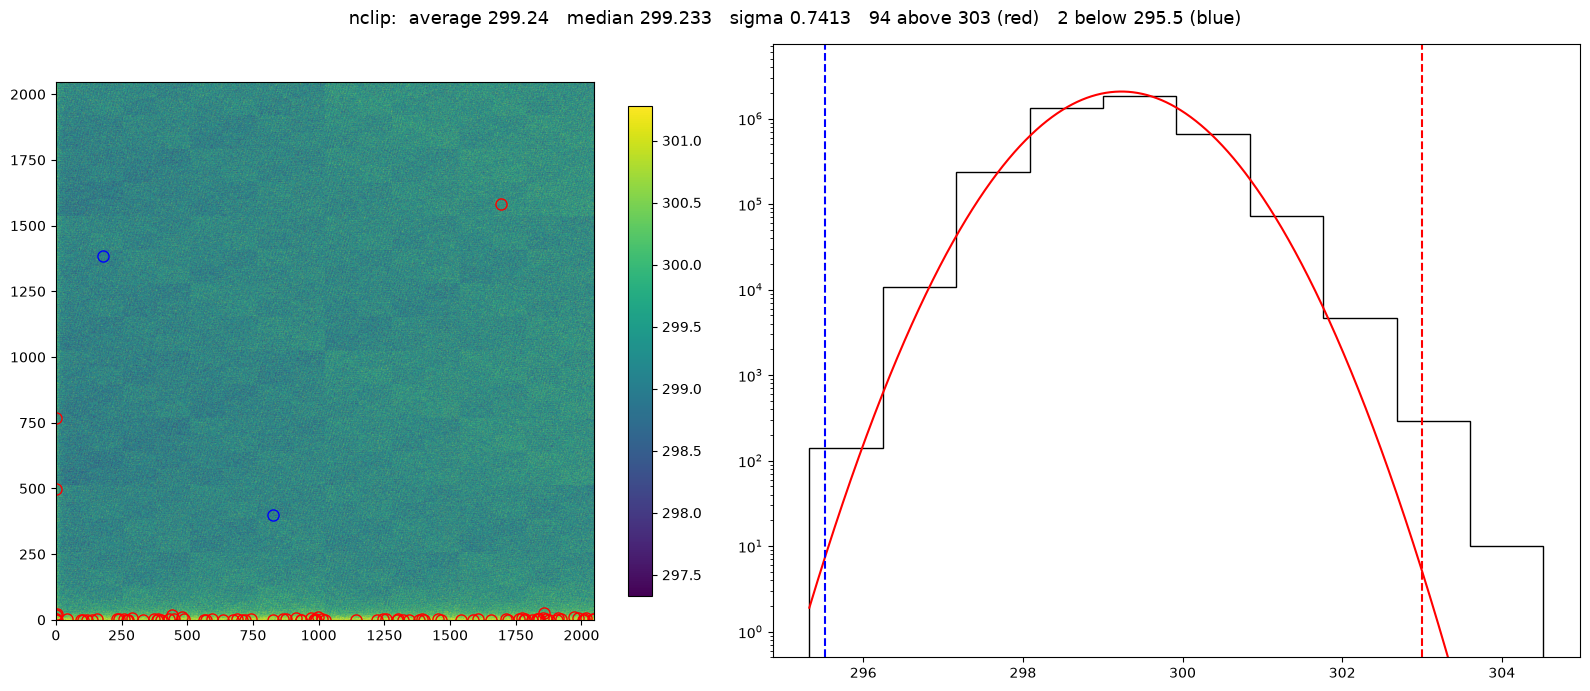

In [75]:
    m = maps['mean']
    mu = np.median(m)
    sigma = 1.4826 * np.median(np.abs(m - mu))


    lo = mu - 5 * sigma

    #hi = mu + 5 * sigma
    hi = 303
    
    vmin = np.percentile(m, 0.5)
    vmax = np.percentile(m, 99.5)

    y_hi, x_hi = np.where(m > hi)
    y_lo, x_lo = np.where(m < lo)


    text = f'{name}:  average {np.mean(m):.6g}   median {mu:.6g}   sigma {sigma:.4g}   {len(x_hi)} above {hi:.4g} (red)   {len(x_lo)} below {lo:.4g} (blue)'
    print(text)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1, 1.2]})
    fig.suptitle(text, fontsize=13)

    # image with the marked pixels: circles, or small dots if there are many
    im = ax1.imshow(m, origin='lower', vmin=vmin, vmax=vmax, cmap='viridis')
    if len(x_hi) + len(x_lo) <= MAX_MARK:
        ax1.plot(x_hi, y_hi, 'o', mfc='none', mec='r', ms=8)
        ax1.plot(x_lo, y_lo, 'o', mfc='none', mec='b', ms=8)
    else:
        ax1.plot(x_hi, y_hi, '.', color='r', ms=2)
        ax1.plot(x_lo, y_lo, '.', color='b', ms=2)
    fig.colorbar(im, ax=ax1, shrink=0.8)

    # histogram with the Gaussian (median, sigma) and the two limits
    v = m.ravel()
    counts, edges, _ = ax2.hist(v,  histtype='step', color='k')
    width = edges[1] - edges[0]  # width of the automatic bins, to scale the Gaussian to the counts
    if sigma > 0:
        x = np.linspace(v.min(), v.max(), 2000)
        gauss = len(v) * width / (sigma * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
        ax2.plot(x, gauss, 'r')

        ax2.axvline(hi, color='r', ls='--')
        ax2.axvline(lo, color='b', ls='--')
        
    ax2.set_yscale('log')
    ax2.set_ylim(0.5, None)


    plt.tight_layout()
    plt.show()

## std

The read noise of every pixel.

std:  average 8.44125   median 8.38041   sigma 0.7446 ADU   485 above 12.1 (red)   0 below 2 (blue)


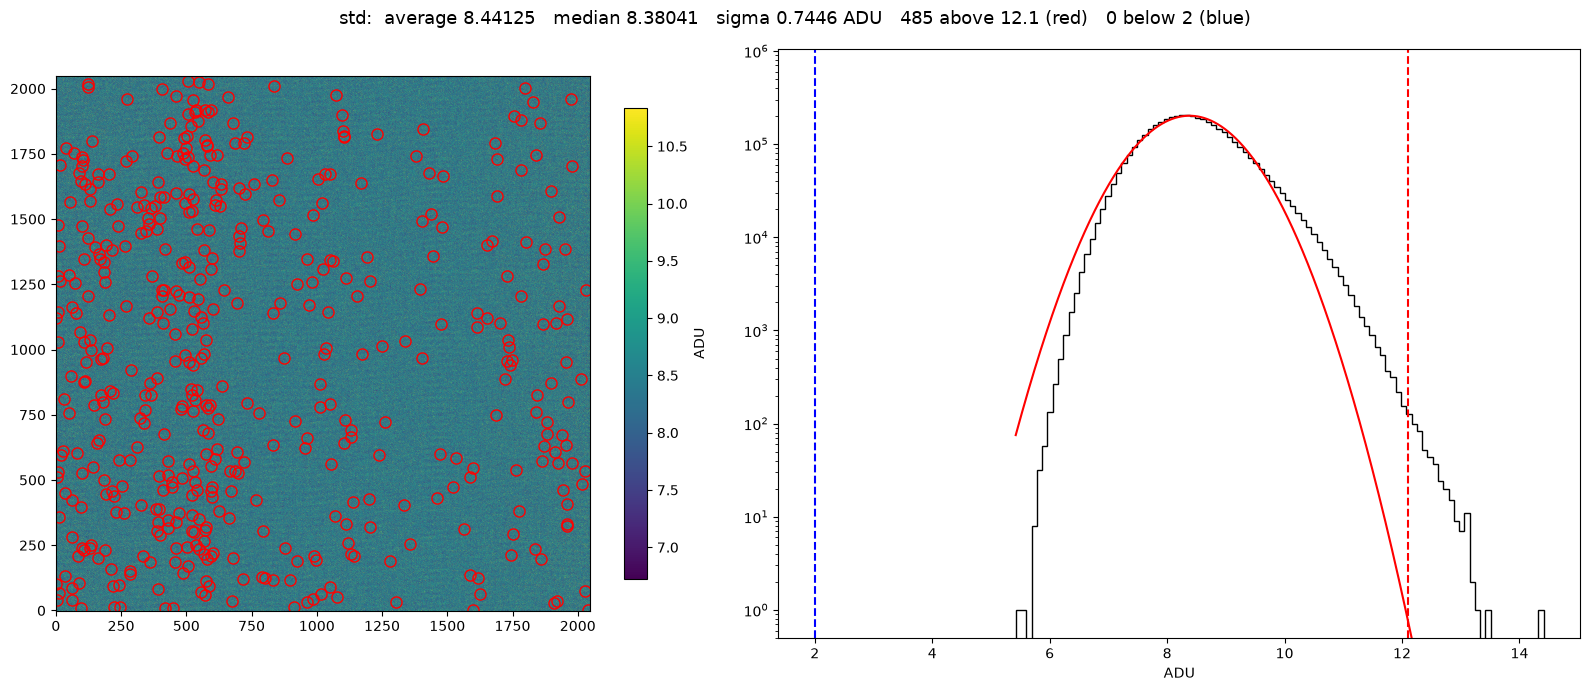

In [76]:
m = maps['std']
mu = np.median(m)
sigma = 1.4826 * np.median(np.abs(m - mu))

# set by hand: pixels below lo are marked blue, above hi red; vmin, vmax = colour scale; bins = number of histogram bins
lo = 2
hi = mu + 5 * sigma
vmin = np.percentile(m, 0.5)
vmax = np.percentile(m, 99.5)
bins = 100

y_hi, x_hi = np.where(m > hi)
y_lo, x_lo = np.where(m < lo)

text = f'std:  average {np.mean(m):.6g}   median {mu:.6g}   sigma {sigma:.4g} ADU   {len(x_hi)} above {hi:.4g} (red)   {len(x_lo)} below {lo:.4g} (blue)'
print(text)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1, 1.2]})
fig.suptitle(text, fontsize=13)

# image with the marked pixels: circles, or small dots if there are more than MAX_MARK
im = ax1.imshow(m, origin='lower', vmin=vmin, vmax=vmax, cmap='viridis')
if len(x_hi) + len(x_lo) <= MAX_MARK:
    ax1.plot(x_hi, y_hi, 'o', mfc='none', mec='r', ms=8)
    ax1.plot(x_lo, y_lo, 'o', mfc='none', mec='b', ms=8)
else:
    ax1.plot(x_hi, y_hi, '.', color='r', ms=2)
    ax1.plot(x_lo, y_lo, '.', color='b', ms=2)
fig.colorbar(im, ax=ax1, shrink=0.8, label='ADU')

# histogram with the Gaussian (median, sigma) and the two limits
v = m.ravel()
counts, edges, _ = ax2.hist(v, bins=bins, histtype='step', color='k')
width = edges[1] - edges[0]  # width of the bins, to scale the Gaussian to the counts
if sigma > 0:
    x = np.linspace(v.min(), v.max(), 2000)
    gauss = len(v) * width / (sigma * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
    ax2.plot(x, gauss, 'r')
ax2.axvline(hi, color='r', ls='--')
ax2.axvline(lo, color='b', ls='--')
ax2.set_yscale('log')
ax2.set_ylim(0.5, None)
ax2.set_xlabel('ADU')

plt.tight_layout()
plt.show()

## nclip

How many values of every pixel were rejected by the clipping (cosmics, unstable pixels). Mostly 0 (then
sigma = 0): `hi = 0.5` marks every pixel with at least one rejected value.

nclip:  average 2.68103   median 3   sigma 1.483 values   17 above 12 (red)   0 below -0.5 (blue)


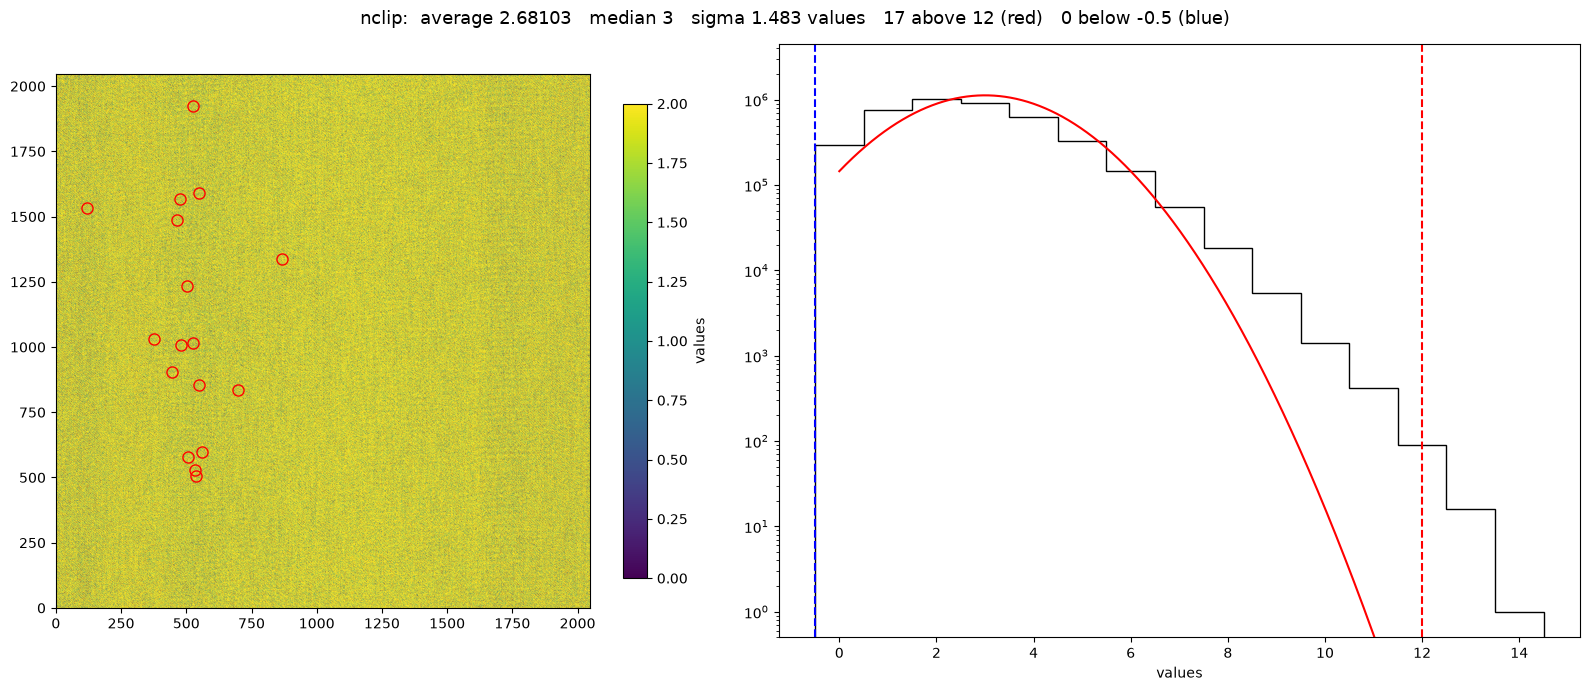

In [77]:
m = maps['nclip']
mu = np.median(m)
sigma = 1.4826 * np.median(np.abs(m - mu))

# set by hand: pixels below lo are marked blue, above hi red; vmin, vmax = colour scale; bins = number of histogram bins
lo = -0.5
hi = 12

vmin = 0
vmax = 2
bins = np.arange(-0.5, m.max() + 1)  # one bin per value

y_hi, x_hi = np.where(m > hi)
y_lo, x_lo = np.where(m < lo)

text = f'nclip:  average {np.mean(m):.6g}   median {mu:.6g}   sigma {sigma:.4g} values   {len(x_hi)} above {hi:.4g} (red)   {len(x_lo)} below {lo:.4g} (blue)'
print(text)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1, 1.2]})
fig.suptitle(text, fontsize=13)

# image with the marked pixels: circles, or small dots if there are more than MAX_MARK
im = ax1.imshow(m, origin='lower', vmin=vmin, vmax=vmax, cmap='viridis')
if len(x_hi) + len(x_lo) <= MAX_MARK:
    ax1.plot(x_hi, y_hi, 'o', mfc='none', mec='r', ms=8)
    ax1.plot(x_lo, y_lo, 'o', mfc='none', mec='b', ms=8)
else:
    ax1.plot(x_hi, y_hi, '.', color='r', ms=2)
    ax1.plot(x_lo, y_lo, '.', color='b', ms=2)
fig.colorbar(im, ax=ax1, shrink=0.8, label='values')

# histogram with the Gaussian (median, sigma) and the two limits
v = m.ravel()
counts, edges, _ = ax2.hist(v, bins=bins, histtype='step', color='k')
width = edges[1] - edges[0]  # width of the bins, to scale the Gaussian to the counts
if sigma > 0:
    x = np.linspace(v.min(), v.max(), 2000)
    gauss = len(v) * width / (sigma * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
    ax2.plot(x, gauss, 'r')
ax2.axvline(hi, color='r', ls='--')
ax2.axvline(lo, color='b', ls='--')
ax2.set_yscale('log')
ax2.set_ylim(0.5, None)
ax2.set_xlabel('values')

plt.tight_layout()
plt.show()